# Member 1: Spark view of the preprocessed Parquet data and ML-ready dataset
Reads `trips_clean/` and `demand_15min/` written by `preprocess_local.ipynb`, explores them with Spark / Spark SQL, and prepares the training dataset. Run top to bottom.

In [1]:
import os, sys, math, json
from pathlib import Path
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler

# ---------------- CONFIG ----------------
OUT_DIR   = os.getenv("OUT_DIR",  r"C:\Angel\big_data_project_updates\data\processed")
DOCS_DIR  = os.getenv("DOCS_DIR", r"C:\Angel\big_data_project_updates\docs")
INTERVAL  = 15
TEST_START = os.getenv("TEST_START", "2020-01-01")   # train: before this date, test: from this date (time-based split)
DRIVER_MEM, CORES = "4g", 4

# ---------------- ENVIRONMENT ----------------
# os.environ["JAVA_HOME"] = r"C:\Program Files\Eclipse Adoptium\jdk-17"
if os.name == "nt":
    hh = os.environ.get("HADOOP_HOME", r"C:\hadoop")
    os.environ["HADOOP_HOME"] = hh
    os.environ["PATH"] += os.pathsep + hh + r"\bin"
    if not Path(hh, "bin", "winutils.exe").exists():
        print("WARNING: winutils.exe not found in", hh + r"\bin")
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

os.makedirs(DOCS_DIR, exist_ok=True)
OUT = OUT_DIR if "://" in OUT_DIR else Path(OUT_DIR).resolve().as_posix()

spark = (SparkSession.builder.appName("taxi-member1-view").master(f"local[{CORES}]")
         .config("spark.driver.memory", DRIVER_MEM)
         .config("spark.sql.session.timeZone", "UTC")
         .config("spark.sql.shuffle.partitions", "64")
         .getOrCreate())
print("Spark", spark.version, "| parallelism:", spark.sparkContext.defaultParallelism, "| UI:", spark.sparkContext.uiWebUrl)

Spark 4.2.0 | parallelism: 4 | UI: http://10.10.18.22:4040


## 1. Load and view the Parquet datasets

In [2]:
trips  = spark.read.parquet(f"{OUT}/trips_clean")
demand = spark.read.parquet(f"{OUT}/demand_{INTERVAL}min")
trips.createOrReplaceTempView("trips")
demand.createOrReplaceTempView("demand")

for name, d in [("trips_clean", trips), ("demand", demand)]:
    print(f"{name}: {d.count():,} rows | {len(d.columns)} columns | {d.rdd.getNumPartitions()} partitions")

trips.printSchema()
trips.show(5, truncate=False)
demand.printSchema()
top_zone = demand.groupBy("zone_id").agg(F.sum("demand").alias("d")).orderBy(F.desc("d")).first()["zone_id"]
demand.where(F.col("zone_id") == top_zone).orderBy("interval_start").show(8)
trips.select("trip_distance", "duration_s", "passenger_count").summary("count", "mean", "min", "50%", "max").show()

trips_clean: 98,660,798 rows | 14 columns | 53 partitions
demand: 13,705,632 rows | 16 columns | 5 partitions
root
 |-- zone_id: integer (nullable = true)
 |-- pickup_ts: timestamp (nullable = true)
 |-- dropoff_ts: timestamp (nullable = true)
 |-- passenger_count: integer (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- duration_s: long (nullable = true)
 |-- pickup_day: integer (nullable = true)
 |-- pickup_hour: integer (nullable = true)
 |-- pickup_weekday: integer (nullable = true)
 |-- is_weekend: integer (nullable = true)
 |-- borough: string (nullable = true)
 |-- zone_name: string (nullable = true)
 |-- pickup_year: integer (nullable = true)
 |-- pickup_month: integer (nullable = true)

+-------+-------------------+-------------------+---------------+-------------+----------+----------+-----------+--------------+----------+---------+----------------------------+-----------+------------+
|zone_id|pickup_ts          |dropoff_ts         |passenger_count|trip_di

## 2. Explore with Spark SQL

In [3]:
print("Trips per month")
spark.sql("""
  SELECT pickup_year AS year, pickup_month AS month, COUNT(*) AS trips,
         ROUND(AVG(trip_distance), 2) AS avg_miles, ROUND(AVG(duration_s) / 60, 1) AS avg_minutes
  FROM trips GROUP BY 1, 2 ORDER BY 1, 2""").show(24)

print("Top 10 pickup zones")
spark.sql("""
  SELECT zone_id, FIRST(borough) AS borough, FIRST(zone_name) AS zone_name, COUNT(*) AS pickups
  FROM trips GROUP BY zone_id ORDER BY pickups DESC LIMIT 10""").show(truncate=False)

print("Average demand per zone and interval by hour: weekday vs weekend")
spark.sql("""
  SELECT hour,
         ROUND(AVG(CASE WHEN is_weekend = 0 THEN demand END), 2) AS weekday_avg,
         ROUND(AVG(CASE WHEN is_weekend = 1 THEN demand END), 2) AS weekend_avg
  FROM demand GROUP BY hour ORDER BY hour""").show(24)

print("Total demand per month")
monthly = spark.sql("""
  SELECT date_format(interval_start, 'yyyy-MM') AS month, SUM(demand) AS total_demand
  FROM demand GROUP BY 1 ORDER BY 1""")
monthly.show(24)

Trips per month
+----+-----+-------+---------+-----------+
|year|month|  trips|avg_miles|avg_minutes|
+----+-----+-------+---------+-----------+
|2019|    1|7406427|     2.83|       13.0|
|2019|    2|6854934|     2.91|       13.8|
|2019|    3|7675131|     3.02|       14.3|
|2019|    4|7264554|     3.02|       14.5|
|2019|    5|7391721|     3.06|       15.1|
|2019|    6|6769760|     3.11|       15.2|
|2019|    7|6147531|     3.15|       14.7|
|2019|    8|5907035|      3.2|       14.5|
|2019|    9|6396012|     3.13|       15.4|
|2019|   10|7038514|     3.05|       15.4|
|2019|   11|6700652|     2.98|       15.0|
|2019|   12|6715844|     3.02|       15.2|
|2020|    1|6230238|     2.93|       13.2|
|2020|    2|6150941|     2.86|       13.6|
|2020|    3|2931220|     2.92|       13.2|
|2020|    4| 226762|     3.11|        9.9|
|2020|    5| 331321|     3.82|       12.0|
|2020|    6| 522201|     3.47|       12.3|
+----+-----+-------+---------+-----------+

Top 10 pickup zones
+-------+--------

## 3. Validate the demand table

In [4]:
n_rows = demand.count()
n_int  = demand.select("interval_start").distinct().count()
n_zone = demand.select("zone_id").distinct().count()
print(f"rows {n_rows:,} = {n_int:,} intervals x {n_zone} zones ->", "OK" if n_rows == n_int * n_zone else "MISMATCH")
assert n_rows == n_int * n_zone

print("Nulls per column (lag/rolling nulls at the start of each zone are expected):")
demand.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in demand.columns]).show(vertical=True)

demand.agg(F.round(F.mean("demand"), 3).alias("mean"), F.max("demand").alias("max"),
           F.round(F.mean((F.col("demand") == 0).cast("int")), 3).alias("share_zero_intervals")).show()

rows 13,705,632 = 52,512 intervals x 261 zones -> OK
Nulls per column (lag/rolling nulls at the start of each zone are expected):
-RECORD 0----------------
 interval_start | 0      
 zone_id        | 0      
 demand         | 0      
 lag_1          | 261    
 lag_2          | 522    
 lag_4          | 1044   
 lag_1d         | 25056  
 lag_1w         | 175392 
 roll_mean_4    | 261    
 roll_mean_1d   | 261    
 hour           | 0      
 slot_of_day    | 0      
 day            | 0      
 weekday        | 0      
 month          | 0      
 is_weekend     | 0      

+-----+---+--------------------+
| mean|max|share_zero_intervals|
+-----+---+--------------------+
|7.199|601|               0.693|
+-----+---+--------------------+



## 4. Prepare the ML-ready dataset

In [5]:
spd = 1440 // INTERVAL                                   # intervals per day
FEATURES = ["zone_id", "hour", "slot_of_day", "weekday", "is_weekend", "month", "day",
            "lag_1", "lag_2", "lag_4", "lag_1d", "lag_1w", "roll_mean_4", "roll_mean_1d",
            "slot_sin", "slot_cos", "weekday_sin", "weekday_cos"]

ml = (demand
      .where(F.col("lag_1w").isNotNull())                # drop the warm-up week of every zone (no full history yet)
      .withColumn("slot_sin", F.sin(2 * math.pi * F.col("slot_of_day") / spd))      # cyclic encodings
      .withColumn("slot_cos", F.cos(2 * math.pi * F.col("slot_of_day") / spd))
      .withColumn("weekday_sin", F.sin(2 * math.pi * F.col("weekday") / 7))
      .withColumn("weekday_cos", F.cos(2 * math.pi * F.col("weekday") / 7))
      .withColumn("label", F.col("demand").cast("double"))
      .withColumn("split", F.when(F.col("interval_start") < F.lit(TEST_START).cast("timestamp"), "train").otherwise("test"))
      .select("interval_start", "split", "label", *FEATURES))

ml_path = f"{OUT}/ml_ready_{INTERVAL}min"
ml.repartition(8).write.mode("overwrite").partitionBy("split").parquet(ml_path)
ml = spark.read.parquet(ml_path)

# checks: no nulls in any feature, time-ordered split with no overlap
nulls = sum(v or 0 for v in ml.select([F.sum(F.col(c).isNull().cast("int")) for c in FEATURES + ["label"]]).first())
assert nulls == 0, f"{nulls} nulls in ML features"
ml.groupBy("split").agg(F.count("*").alias("rows"), F.min("interval_start").alias("from"),
                        F.max("interval_start").alias("to")).orderBy("split").show(truncate=False)

+-----+-------+-------------------+-------------------+
|split|rows   |from               |to                 |
+-----+-------+-------------------+-------------------+
|test |4560192|2020-01-01 00:00:00|2020-06-30 23:45:00|
|train|8970048|2019-01-08 00:00:00|2019-12-31 23:45:00|
+-----+-------+-------------------+-------------------+



## 5. Spark MLlib input and sanity baseline

In [6]:
# vector form for Spark MLlib models (RandomForestRegressor, GBTRegressor, ...)
assembler = VectorAssembler(inputCols=FEATURES, outputCol="features")
assembler.transform(ml.where("split = 'train'").limit(3)).select("features", "label").show(3, truncate=60)

# naive reference: predict demand = same time last week. Not Member 2's model, only a reference for MAE / RMSE.
base = (ml.withColumn("err", F.col("label") - F.col("lag_1w"))
          .groupBy("split").agg(F.round(F.avg(F.abs("err")), 3).alias("MAE"),
                                F.round(F.sqrt(F.avg(F.col("err") ** 2)), 3).alias("RMSE")))
base.show()

+------------------------------------------------------------+-----+
|                                                    features|label|
+------------------------------------------------------------+-----+
|[224.0,10.0,43.0,4.0,0.0,3.0,22.0,4.0,6.0,13.0,4.0,6.0,7....|  6.0|
|[224.0,7.0,30.0,2.0,0.0,5.0,22.0,14.0,8.0,10.0,13.0,23.0,...| 14.0|
|[186.0,13.0,53.0,1.0,0.0,9.0,17.0,108.0,129.0,105.0,55.0,...| 68.0|
+------------------------------------------------------------+-----+

+-----+-----+-----+
|split|  MAE| RMSE|
+-----+-----+-----+
|train| 2.37|7.861|
| test|1.338|5.943|
+-----+-----+-----+



## 6. Plots (optional)

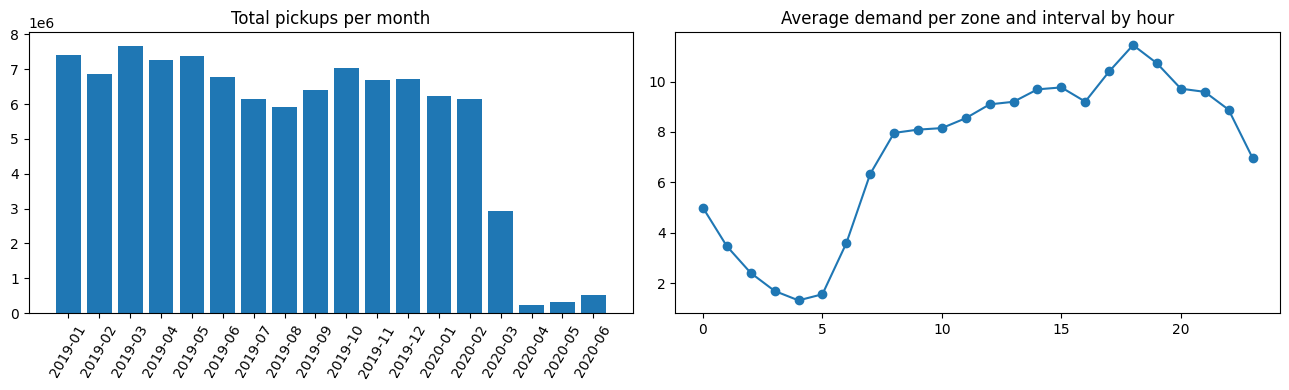

In [7]:
try:
    import matplotlib.pyplot as plt
    m = monthly.toPandas()
    h = spark.sql("SELECT hour, AVG(demand) AS avg_demand FROM demand GROUP BY hour ORDER BY hour").toPandas()
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].bar(m["month"], m["total_demand"]); ax[0].set_title("Total pickups per month"); ax[0].tick_params(axis="x", rotation=60)
    ax[1].plot(h["hour"], h["avg_demand"], marker="o"); ax[1].set_title("Average demand per zone and interval by hour")
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed: pip install matplotlib")

## Output
`ml_ready_15min/` (Parquet, partitioned by `split` = train / test): `interval_start`, `label` (= demand), 18 feature columns. The warm-up week of each zone is removed, so no feature is null.
Split by time (`TEST_START`): train = before 2020-01-01, test = 2020-01-01 onwards (includes the COVID shift). Members 2 and 3 can re-slice the same table by `interval_start` for periodic retraining.